In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import os

<h1>1.0 Import Ride and Zone Lookup Data</h1>

<h2>1.1 Import Ride Data</h2>

In [2]:

import pandas as pd
import os

def load_rides_data_manhattan(
    file_prefix,
    max_index,
    folder_path="../dataset",
):
    """
    Load multiple CSV files and filter to Manhattan zones immediately.

    Parameters
    ----------
    file_prefix : str
        e.g. "rides_train_"
    max_index : int
        Last index (inclusive)
    folder_path : str

    Returns
    -------
    pd.DataFrame
    """

    # Convert to set for fast lookup
    zones = pd.read_csv('../dataset/taxi_zone_lookup.csv')
    manhat_zones = set(zones[zones['Borough'] == 'Manhattan']['LocationID'])

    dtype_dict = {
        "VendorID": "int8",
        "tpep_pickup_datetime": "string",
        "tpep_dropoff_datetime": "string",
        "passenger_count": "float32",
        "trip_distance": "float32",
        "RatecodeID": "category",
        "store_and_fwd_flag": "category",
        "PULocationID": "int16",
        "DOLocationID": "int16",
        "payment_type": "int8",
        "fare_amount": "float32",
        "extra": "float32",
        "mta_tax": "float32",
        "tip_amount": "float32",
        "tolls_amount": "float32",
        "improvement_surcharge": "float32",
        "total_amount": "float32",
        "congestion_surcharge": "float32",
        "Airport_fee": "float32",
    }

    dfs = []

    for i in range(max_index + 1):
        file_path = os.path.join(folder_path, f"{file_prefix}{i}.csv")
        
        print(f"Loading {file_path}... ", end="")
        df = pd.read_csv(file_path, dtype=dtype_dict)
        dfs.append(df[df["PULocationID"].isin(manhat_zones)])
        print(f" {len(df)} rows in Manhattan")


    assert(len(dfs) > 0)

    combined = pd.concat(dfs, ignore_index=True, copy=False)
    print(f"\nFinal shape after concat: {combined.shape}")
    return combined

In [3]:
rides = load_rides_data_manhattan(
    file_prefix="rides_train_",
    max_index=10,
)

Loading ../dataset/rides_train_0.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_1.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_2.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_3.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_4.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_5.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_6.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_7.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_8.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_9.csv...  3000000 rows in Manhattan
Loading ../dataset/rides_train_10.csv...  1289368 rows in Manhattan

Final shape after concat: (27633290, 20)


<h2>1.3 Check Data Imports</h2>

In [4]:
rides.head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
0,0,1,2024-04-01 00:02:40,2024-04-01 00:30:42,0.0,5.20,1.0,N,161,7,1,29.6,3.5,0.5,8.65,0.0,1.0,43.25,2.5,0.0
1,2,2,2024-04-01 00:48:42,2024-04-01 01:05:30,1.0,3.55,1.0,N,186,236,1,20.5,1.0,0.5,5.10,0.0,1.0,30.60,2.5,0.0
2,3,2,2024-04-01 00:56:02,2024-04-01 01:05:09,1.0,1.06,1.0,N,137,164,2,10.0,1.0,0.5,0.00,0.0,1.0,15.00,2.5,0.0
3,4,1,2024-04-01 00:08:32,2024-04-01 00:10:24,1.0,0.70,1.0,N,236,263,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0
4,5,2,2024-04-01 00:16:09,2024-04-01 00:20:53,1.0,1.63,1.0,N,142,68,2,8.6,1.0,0.5,0.00,0.0,1.0,13.60,2.5,0.0


In [5]:
rides.describe()

,Unnamed: 0,VendorID,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
count,2.763329e+07,2.763329e+07,2.496930e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.763329e+07,2.496930e+07,2.496930e+07
mean,1.678523e+06,1.764726e+00,1.330433e+00,3.641988e+00,1.682043e+02,1.650518e+02,1.101075e+00,1.571977e+01,1.239680e+00,4.829569e-01,2.825162e+00,2.347591e-01,9.708499e-01,2.333420e+01,2.365623e+00,1.396815e-04
std,1.110347e+06,4.245956e-01,8.177385e-01,3.745468e+02,6.530407e+01,6.864552e+01,6.334606e-01,6.588833e+01,1.506391e+00,1.215137e-01,3.076578e+00,1.621543e+00,2.337268e-01,6.658820e+01,7.019455e-01,1.700921e-02
min,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00,1.000000e+00,0.000000e+00,-9.800000e+02,-7.500000e+00,-5.000000e-01,-3.000000e+02,-8.430000e+01,-1.000000e+00,-9.835000e+02,-2.500000e+00,-1.750000e+00
25%,6.540230e+05,2.000000e+00,1.000000e+00,9.800000e-01,1.370000e+02,1.140000e+02,1.000000e+00,8.600000e+00,0.000000e+00,5.000000e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.540000e+01,2.500000e+00,0.000000e+00
50%,1.394649e+06,2.000000e+00,1.000000e+00,1.600000e+00,1.630000e+02,1.620000e+02,1.000000e+00,1.280000e+01,1.000000e+00,5.000000e-01,2.560000e+00,0.000000e+00,1.000000e+00,1.990000e+01,2.500000e+00,0.000000e+00
75%,2.688998e+06,2.000000e+00,1.000000e+00,2.670000e+00,2.340000e+02,2.340000e+02,1.000000e+00,1.910000e+01,2.500000e+00,5.000000e-01,3.980000e+00,0.000000e+00,1.000000e+00,2.690000e+01,2.500000e+00,0.000000e+00
max,3.833770e+06,7.000000e+00,9.000000e+00,3.986086e+05,2.630000e+02,2.650000e+02,5.000000e+00,3.355444e+05,1.444000e+01,3.584000e+01,9.999900e+02,1.702880e+03,1.000000e+00,3.355509e+05,2.520000e+00,1.750000e+00


<h1>2.0 Exploring the Data</h1>

<h2>2.3 Check for missing data in general</h2>

In [6]:
print(rides.isna().mean() * 100)

Unnamed: 0               0.000000
VendorID                 0.000000
tpep_pickup_datetime     0.000000
tpep_dropoff_datetime    0.000000
passenger_count          9.640506
trip_distance            0.000000
RatecodeID               9.640506
store_and_fwd_flag       9.640506
PULocationID             0.000000
DOLocationID             0.000000
payment_type             0.000000
fare_amount              0.000000
extra                    0.000000
mta_tax                  0.000000
tip_amount               0.000000
tolls_amount             0.000000
improvement_surcharge    0.000000
total_amount             0.000000
congestion_surcharge     9.640506
Airport_fee              9.640506
dtype: float64


<h2>2.4 Check for missing data by vendor</h2>

In [7]:
missing_by_vendor = (
    rides
    .groupby("VendorID")
    .agg(lambda x: x.isna().mean())
    * 100
).round(5)

missing_by_vendor = missing_by_vendor.loc[:, (missing_by_vendor > 0).any()]

print(missing_by_vendor)

          passenger_count  RatecodeID  store_and_fwd_flag  \
VendorID                                                    
1                 9.04186     9.04186             9.04186   
2                 9.82345     9.82345             9.82345   
6               100.00000   100.00000           100.00000   
7                 0.00000     0.00000             0.00000   

          congestion_surcharge  Airport_fee  
VendorID                                     
1                      9.04186      9.04186  
2                      9.82345      9.82345  
6                    100.00000    100.00000  
7                      0.00000      0.00000  


<h2>2.5 Updating data types</h2>

In [8]:
# Convert to datetime
rides['tpep_pickup_datetime'] = pd.to_datetime(
    rides['tpep_pickup_datetime'],
    errors='coerce'
)

rides['tpep_dropoff_datetime'] = pd.to_datetime(
    rides['tpep_dropoff_datetime'],
    errors='coerce'
)

# Convert Y/N to boolean
rides['store_and_fwd_flag'] = (
    rides['store_and_fwd_flag']
    .map({'Y': True, 'N': False})
    .astype('boolean') # just for reference clarity
)

<h2>2.6 Check data types</h2>

In [9]:
rides.dtypes

Unnamed: 0                        int64
VendorID                           int8
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float32
trip_distance                   float32
RatecodeID                     category
store_and_fwd_flag              boolean
PULocationID                      int16
DOLocationID                      int16
payment_type                       int8
fare_amount                     float32
extra                           float32
mta_tax                         float32
tip_amount                      float32
tolls_amount                    float32
improvement_surcharge           float32
total_amount                    float32
congestion_surcharge            float32
Airport_fee                     float32
dtype: object

<h2>2.7 Add a duration and avg speed column for validation</h2>

In [10]:
# Duration in hours
rides['duration_hours'] = (
    (rides['tpep_dropoff_datetime'] - rides['tpep_pickup_datetime'])
    .dt.total_seconds() / 3600
)

# Average speed (mph)
rides['avg_speed_mph'] = (
    rides['trip_distance'] /
    rides['duration_hours'].replace(0, np.nan)
)

<h2>2.8 Feature plotting for understanding</h2>

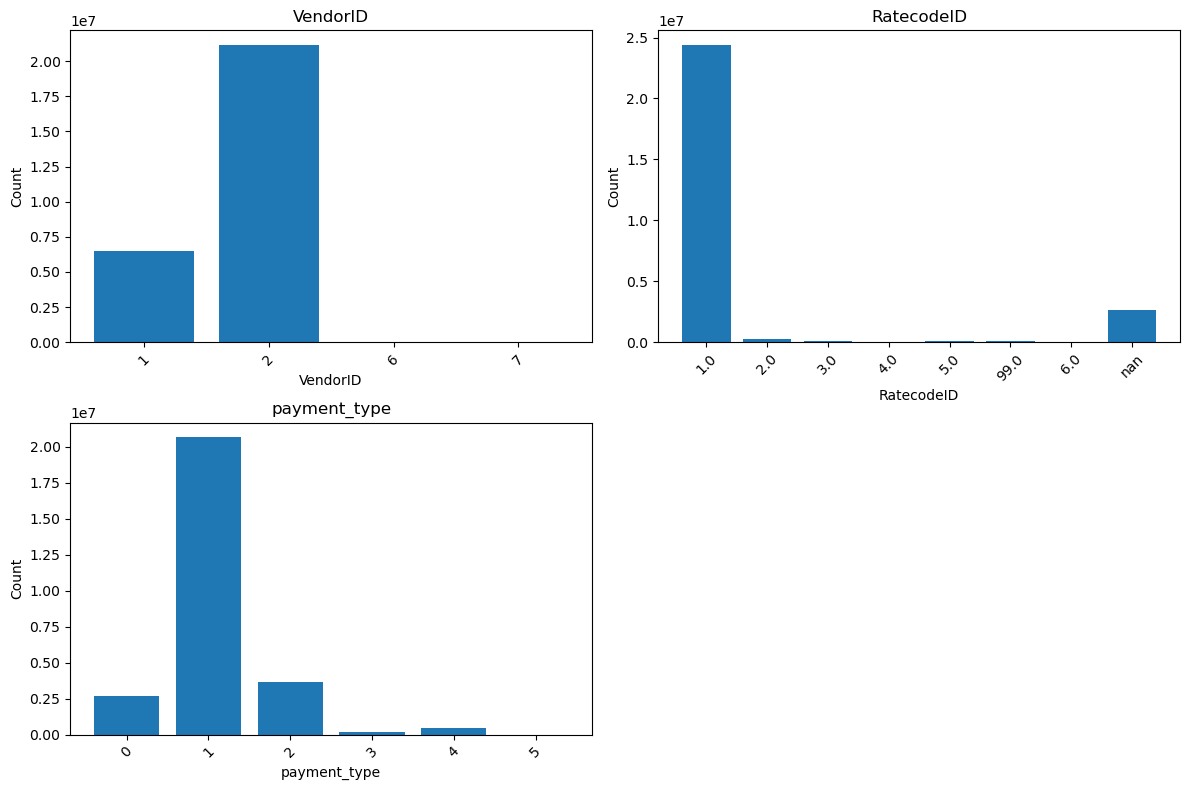

In [11]:
# label the cateogricals - ignore "store_and_fwd_flag" because it is not at all useful.
raw_categorical = [
    "VendorID",
    "RatecodeID",
    "payment_type",
]

# Construct some bar charts of the categorical variables so we can see the distribution and observe outliers.

n = len(raw_categorical)
cols = 2
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(raw_categorical):
    counts = rides[col].value_counts(dropna=False).sort_index()
    
    axes[i].bar(counts.index.astype(str), counts.values)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

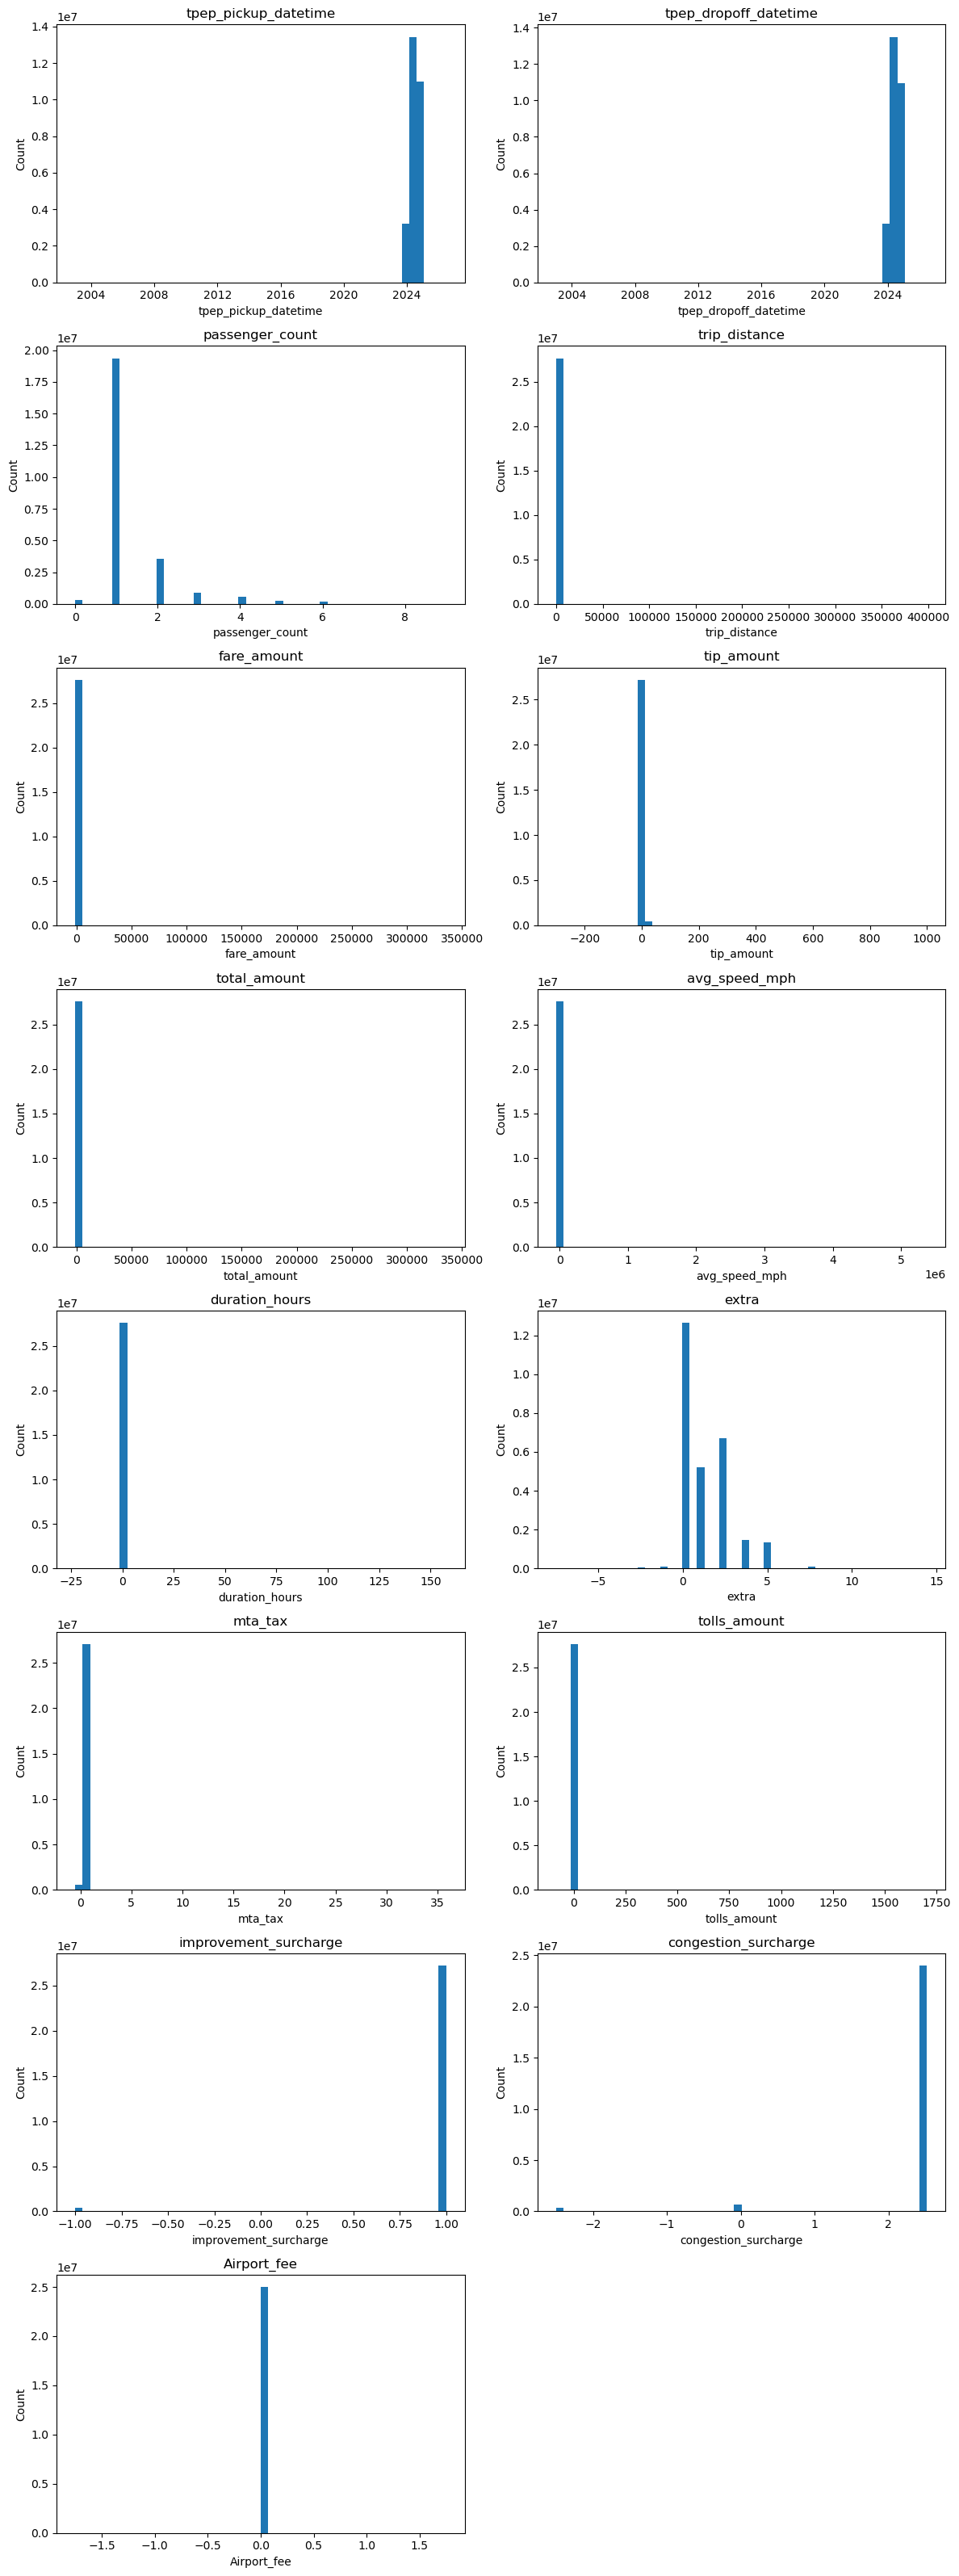

In [12]:
raw_numeric = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount",
    "avg_speed_mph",
    "duration_hours",
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "Airport_fee"
]

# Construct some binned histograms of the numerical variables so we can see the distribution and observe outliers.


n = len(raw_numeric)
cols = 2
rows = int(np.ceil(n / cols))

fig, axes = plt.subplots(rows, cols, figsize=(12, 4 * rows))
axes = axes.flatten()

for i, col in enumerate(raw_numeric):
    axes[i].hist(rides[col].dropna(), bins=50)
    axes[i].set_title(col)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

/var/folders/71/kx91_0cj091f40v5pnjfn3640000gn/T/ipykernel_16320/3218094566.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_fare_by_rate = rides.groupby("RatecodeID")["fare_amount"].mean().reset_index()


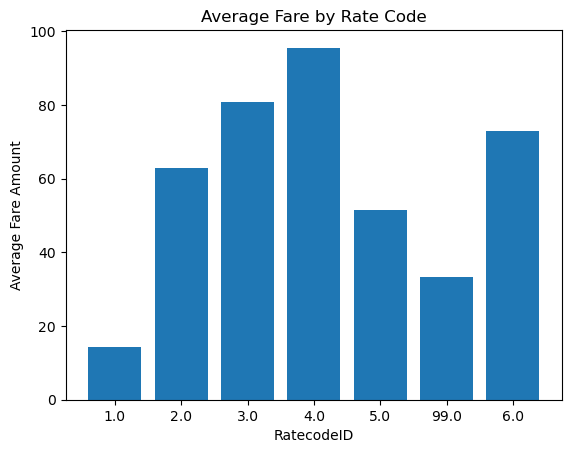

In [13]:
avg_fare_by_rate = rides.groupby("RatecodeID")["fare_amount"].mean().reset_index()

plt.figure()
plt.bar(avg_fare_by_rate["RatecodeID"], avg_fare_by_rate["fare_amount"])

plt.xlabel("RatecodeID")
plt.ylabel("Average Fare Amount")
plt.title("Average Fare by Rate Code")

plt.xticks(avg_fare_by_rate["RatecodeID"])
plt.show()

<h2>2.9 Preliminary feature evaluation</h2>

| Feature                  | Type        | Missing Data | Probably Important | Sig. Outliers | Notes |
|--------------------------|------------|------|------|------|------|
| VendorID                | Categorical | No | No | N/A |  |
| tpep_pickup_datetime    | Datetime    | No | Yes | N/A | Needs conversion |
| tpep_dropoff_datetime   | Datetime    | No | Yes | N/A | Same, leakage risk! |
| passenger_count         | Discrete    | Yes | No | No | Leakage risk|
| trip_distance           | Continuous  | No | No | Yes | Leakage risk|
| RatecodeID              | Categorical | Yes | Yes | No |  | Large differences in avg fare
| store_and_fwd_flag      | Boolean     | Yes | No | No | Apparently useless |
| PULocationID            | Categorical | No | Yes | No |  |
| DOLocationID            | Categorical | No | Yes | No |  |
| payment_type            | Categorical | No | No | No |  |
| fare_amount             | Continuous  | No | No | Yes | Part of revenue |
| extra                   | Continuous  | No | No | No | Part of revenue |
| mta_tax                 | Continuous  | No | No | Yes* | Part of revenue; *do not make a big difference as numbers are small |
| tip_amount              | Continuous  | No | No | No | Part of revenue |
| tolls_amount            | Continuous  | No | No | No | Part of revenue |
| improvement_surcharge   | Continuous  | No | No | No | Part of revenue |
| total_amount            | Continuous  | No | Yes | Yes |  Target variable (revenue) |
| congestion_surcharge    | Continuous  | Yes | No | No | Part of revenue |
| airport_fee             | Continuous  | Yes | No | No | Part of revenue |
| duration_hours          | Continuous  | No | Yes | Yes | Massive outliers |
| avg_speed_mph           | Continuous  | No | Yes | Yes | Massive outliers |

<h1>3.0 Finding Data Discrepancies and Cleaning</h1>

In [14]:
# Based on the above, we want to investigate trip_distance, fare_amount, mta_tax, total_amount, duration_hours, avg_speed_mph

# All negative values must be removed.

# Need to determine cut-off points for the others, to prevent enormous outliers from biasing the models.
# Below, we try some potential cut-offs and oberve ho

print("Counts of extreme / invalid values:\n")

checks = {
    "total_amount > 1000": ("total_amount", rides["total_amount"] > 1000),
    "total_amount < 0.0": ("total_amount", rides["total_amount"] <= 0.0),
    "avg_speed_mph > 150": ("avg_speed_mph", rides["avg_speed_mph"] > 150),
    "avg_speed_mph < 1": ("avg_speed_mph", rides["avg_speed_mph"] < 1),
    "duration_hours > 12": ("duration_hours", rides["duration_hours"] > 12),
    "duration_hours < 0.01": ("duration_hours", rides["duration_hours"] < 0.01),
}

for name, (col, condition) in checks.items():
    full_col = rides[col]
    flagged = full_col[condition]
    count = condition.sum()

    if count > 0:
        # quantile position in the FULL distribution
        q_low = (full_col <= flagged.min()).mean()
        q_high = (full_col <= flagged.max()).mean()

        print(
            f"{name}: {count} | "
            f"value range: {flagged.min():.4f} to {flagged.max():.4f} | "
            f"full-sample quantile range: {q_low:.4f} to {q_high:.4f}"
        )
    else:
        print(f"{name}: {count}")

Counts of extreme / invalid values:

total_amount > 1000: 11 | value range: 1007.9800 to 335550.9375 | full-sample quantile range: 1.0000 to 1.0000
total_amount < 0.0: 368413 | value range: -983.5000 to 0.0000 | full-sample quantile range: 0.0000 to 0.0133
avg_speed_mph > 150: 4448 | value range: 150.6977 to 5379164.3750 | full-sample quantile range: 0.9996 to 0.9998
avg_speed_mph < 1: 485432 | value range: -50562.0003 to 1.0000 | full-sample quantile range: 0.0000 to 0.0176
duration_hours > 12: 13123 | value range: 12.0172 to 157.5900 | full-sample quantile range: 0.9995 to 1.0000
duration_hours < 0.01: 191407 | value range: -22.9111 to 0.0097 | full-sample quantile range: 0.0000 to 0.0069


<h2>3.1 Finding unphysical data</h2>

In [15]:
def get_constraint_violations(df):

    violations = {}
    # These are the cut-offs we apply to the data. They are decided and refined using statistical assessment in 3.0 and checked using 3.2
    # The conditions describe what data will be flagged
    possible_checks = {
        'passenger_count': lambda x: x < 0,
        'trip_distance': lambda x: (x <= 0) | (x > 400), # to ensure the taxi actually moved
        'fare_amount': lambda x: (x < 0) | (x > 3000),
        'extra': lambda x: x < 0,
        'mta_tax': lambda x: x < 0,
        'tip_amount': lambda x: x < 0,
        'tolls_amount': lambda x: x < 0,
        'improvement_surcharge': lambda x: x < 0,
        'total_amount': lambda x: x < 0,
        'congestion_surcharge': lambda x: x < 0,
        'Airport_fee': lambda x: x < 0,
        'duration_hours': lambda x: (x < 0.01) | (x > 12), # to remove any entries which took zero time
        'avg_speed_mph': lambda x: (x <= 0) | (x > 150), # to remove any entries which suggest the taxi has moved unrealistically far in a given time.
        'tpep_pickup_datetime': lambda x: (x < "2024-01-01") | (x >= "2025-01-01")
    }

    # Column-based checks
    for col, condition in possible_checks.items():
        if col in df.columns:
            mask = condition(df[col])
            violations[col] = df.index[mask].tolist()

    # Datetime check
    if 'tpep_pickup_datetime' in df.columns and 'tpep_dropoff_datetime' in df.columns:
        mask = df['tpep_dropoff_datetime'] < df['tpep_pickup_datetime']
        violations['pickup_before_dropoff'] = df.index[mask].tolist()

    # Combine all violating indices
    all_bad_indices = set()
    for v in violations.values():
        all_bad_indices.update(v)

    return violations, all_bad_indices

In [16]:
# Get the violation df and the row numbers of offending data entries
violations, bad_idx = get_constraint_violations(rides)

# Print a summary in order to check how much is flagged. We want this to be relatively small compared to sample size.
print({k: len(v) for k, v in violations.items()})
print(f"Total bad rows: {len(bad_idx)}")

{'passenger_count': 0, 'trip_distance': 428887, 'fare_amount': 449515, 'extra': 177440, 'mta_tax': 355236, 'tip_amount': 451, 'tolls_amount': 11221, 'improvement_surcharge': 364068, 'total_amount': 365896, 'congestion_surcharge': 349260, 'Airport_fee': 183, 'duration_hours': 204530, 'avg_speed_mph': 427564, 'tpep_pickup_datetime': 37, 'pickup_before_dropoff': 1033}
Total bad rows: 904070


In [17]:
#Inspect the bad rows in case of suspicion
rides.loc[list(bad_idx)].head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
4194308,2840859,2,2024-10-26 17:20:34,2024-10-26 17:30:45,1.0,1.04,1.0,False,161,163,...,0.0,-0.5,0.0,0.00,-1.0,-14.700000,-2.5,0.0,0.169722,6.127659
20971528,3236614,1,2024-03-08 09:38:26,2024-03-08 09:38:31,NaN,0.00,NaN,<NA>,163,163,...,0.0,0.5,0.0,0.00,1.0,10.830000,NaN,NaN,0.001389,0.000000
2097161,3116510,2,2024-04-02 09:19:06,2024-04-02 09:33:39,NaN,1.50,NaN,<NA>,79,125,...,0.0,0.5,0.0,0.00,1.0,2.220000,NaN,NaN,0.242500,6.185567
2097162,3116511,2,2024-04-02 09:20:28,2024-04-02 09:31:21,NaN,1.44,NaN,<NA>,79,234,...,0.0,0.5,0.0,0.00,1.0,3.000000,NaN,NaN,0.181389,7.938745
12582920,801061,2,2024-06-08 10:41:20,2024-06-08 11:20:02,2.0,17.23,2.0,False,230,132,...,0.0,-0.5,0.0,-6.94,-1.0,-80.940002,-2.5,0.0,0.645000,26.713178


<h2>3.2 Removing unphysical data</h2>

In [18]:
rides_clean = rides.drop(index=bad_idx)

#Quick check - sould see the rows disappear
print(rides.shape)
print(rides_clean.shape)

(27633290, 22)
(26729220, 22)


<h2>3.3 Check for statistically suspicious data (to validate cut-off choices)</h2>

In [19]:
# Have a look at statistics
rides_clean.describe().loc[['mean', 'std', 'max', 'min']]

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
mean,1.665981e+06,1.762917,2024-07-04 06:55:04.893386496,2024-07-04 07:09:37.946069504,1.329234,2.420961,168.375136,165.171522,1.075101,16.056780,1.282282,0.497323,2.882207,0.241068,0.997422,23.873606,2.441330,0.000110,0.242515,9.729961
std,1.105279e+06,0.425455,NaN,NaN,0.817062,2.756828,65.225623,68.605955,0.555448,11.954696,1.494237,0.037945,3.025478,1.607666,0.050500,14.900706,0.378459,0.013886,0.182018,4.860315
max,3.833770e+06,6.000000,2024-12-31 23:59:58,2025-01-01 09:47:37,9.000000,344.600006,263.000000,265.000000,4.000000,1611.599976,14.440000,35.840000,999.989990,1702.880005,1.000000,1737.180054,2.520000,1.750000,11.999722,150.000000
min,0.000000e+00,1.000000,2024-01-01 00:00:00,2024-01-01 00:02:42,0.000000,0.010000,4.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.010000,0.000980


In [20]:
# Check toll amounts manually as they seem a bit high. All checks out.
print(rides_clean[rides_clean['tolls_amount'] > 50]['tolls_amount'])

292679        87.940002
299790        69.129997
383170        53.380001
534155      1702.880005
1048614       59.380001
               ...     
25952113      69.400002
26181343      52.380001
26309738      66.000000
26351168     476.350006
27077878      70.000000
Name: tolls_amount, Length: 115, dtype: float32


In [21]:


# Numerical features to be tested (judged using above describe() print and particularly maxima
# All maxima are satisfactory. 'tolls_amount' needed extra analysis, but all seems in order. We now Z-test the remaining features.
# Note fare_amount <= total_amount
iqrtest_features = [
    'trip_distance',
    'total_amount',
]

def get_iqr_violations(df, features, k=1.5):

    # Store flagged row indices separately for each feature
    violations = {}
    # Store flagged row indices separately for each feature
    flagged_rows = []
    # Store all unique bad row indices across all tested features
    bad_idx = set()

    # Loop through each feature that's selected
    for col in features:
        # Skip if not in the dataframe
        if col not in df.columns:
            continue

        # If the column has no non-missing values, record no violations
        x = df[col].dropna()
        if x.empty:
            violations[col] = []
            continue

        # Quantiles
        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        # Interquantile range (IQR)
        iqr = q3 - q1

       # Thresholds
        lower = q1 - k * iqr
        upper = q3 + k * iqr

        # Flag rows lying outside acceptable range
        mask = (df[col] < lower) | (df[col] > upper)
        idx_list = df.index[mask.fillna(False)].tolist()

        # Store violating row numbers
        violations[col] = idx_list
        # Add bad row numbers to the set
        bad_idx.update(idx_list)

        # Store some info on each flagged row (for review)
        for idx in idx_list:
            flagged_rows.append({
                'row_index': idx,
                'feature': col,
                'value': df.at[idx, col]
            })

    flagged_df = pd.DataFrame(flagged_rows)

    return violations, flagged_df, bad_idx

In [22]:
violations_iqr, flagged_iqr_df, bad_idx_iqr = get_iqr_violations(
    rides_clean,
    features=iqrtest_features,
    k=5 # adjust for sensitivity
)

In [23]:
flagged_iqr_df.sort_values(by='value')

,row_index,feature,value
390330,19975879,trip_distance,11.210000
265467,13325620,trip_distance,11.210000
311031,15606002,trip_distance,11.210000
82694,4232209,trip_distance,11.210000
406020,20777196,trip_distance,11.210000
...,...,...,...
788317,19012940,total_amount,1021.989990
680762,10653280,total_amount,1111.540039
681902,10750092,total_amount,1599.000000
752738,15912407,total_amount,1647.979980


In [24]:
# Have a look at the number of flagged entries in each selected feature.
print({k: len(v) for k, v in violations_iqr.items()})
print(f"Total unique bad rows: {len(bad_idx_iqr)}")

{'trip_distance': 538834, 'total_amount': 356793}
Total unique bad rows: 567232


In [25]:
# Inspect original rows (very many)
# TODO: original as in `rides` or `rides_clean`?
rides[['duration_hours', 'avg_speed_mph', 'trip_distance', 'total_amount', 'fare_amount', 'PULocationID', 'DOLocationID']].loc[list(bad_idx_iqr)].sort_values(by='total_amount', ascending=False)

,duration_hours,avg_speed_mph,trip_distance,total_amount,fare_amount,PULocationID,DOLocationID
534155,0.466111,10.727056,5.000000,1737.180054,30.299999,234,226
15912407,5.916389,37.840651,223.880005,1647.979980,1611.599976,75,265
10750092,4.072778,57.307324,233.399994,1599.000000,1592.000000,79,265
10653280,3.120000,51.682692,161.250000,1111.540039,1097.099976,79,138
19012940,0.226111,16.805897,3.800000,1021.989990,17.000000,79,43
...,...,...,...,...,...,...,...
7379554,1.000278,15.745626,15.750000,0.000000,2.900000,24,215
14476982,1.166944,9.940491,11.600000,0.000000,0.000000,42,263
15600580,0.374167,33.193764,12.420000,0.000000,0.000000,127,75
26660834,0.607222,30.795976,18.700001,0.000000,0.000000,263,132


In [26]:
rides_clean.dtypes
rides_clean.shape

(26729220, 22)

## 4.1 Save cleaned file to disk

In [27]:
rides_clean.sort_values("tpep_pickup_datetime").head()

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,duration_hours,avg_speed_mph
21206378,2506,1,2024-01-01 00:00:00,2024-01-01 00:02:49,1.0,0.30,1.0,False,140,140,...,3.5,0.5,1.85,0.00,1.0,11.250000,2.5,0.0,0.046944,6.390533
21206574,2712,2,2024-01-01 00:00:02,2024-01-01 00:04:36,2.0,1.57,1.0,False,161,236,...,1.0,0.5,2.72,0.00,1.0,16.320000,2.5,0.0,0.076111,20.627738
21209181,5501,2,2024-01-01 00:00:04,2024-01-01 00:22:32,1.0,7.37,1.0,False,125,157,...,1.0,0.5,0.00,0.00,1.0,38.799999,2.5,0.0,0.374444,19.682492
21207814,4025,2,2024-01-01 00:00:11,2024-01-01 00:19:43,1.0,9.55,1.0,False,229,181,...,1.0,0.5,8.60,0.00,1.0,51.599998,2.5,0.0,0.325556,29.334472
21205235,1316,2,2024-01-01 00:00:11,2024-01-01 00:42:33,1.0,9.89,4.0,False,234,265,...,1.0,0.0,0.00,12.75,1.0,96.150002,0.0,0.0,0.706111,14.006295


In [28]:
def to_split_csv(
    df,
    prefix,
    rows_per_file=1800000,
):
    for i in range(0, int(len(df) / rows_per_file)):
        df[i*rows_per_file:(i+1)*rows_per_file].to_csv(f"{prefix}_{i:02}.csv")

In [29]:
to_split_csv(
    rides_clean.sort_values("tpep_pickup_datetime"),
    "../dataset-clean/rides_train",
)